# Notebook 02: Order Matching and Priority Rules

**Paper Reference:** Gould et al. (2013), Section 3 — *Challenges of Studying LOBs*

This notebook explores:
1. **Price-time priority** — the standard matching rule
2. **Pro-rata matching** — an alternative used in some futures markets
3. How priority rules affect fill sequences and trader incentives
4. State-space complexity of LOBs

In [1]:
import sys
sys.path.insert(0, '..')

from lob.order import limit_order, market_order, Side, reset_order_id_counter
from lob.book import OrderBook
from lob.matching import PriceTimeEngine, ProRataEngine
from lob.analysis.plotting import set_style
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

set_style()
reset_order_id_counter()

## 1. Price-Time Priority

From the paper (Section 3.4): *"Most LOBs use price-time priority, which assigns a unique priority to each active order. An active order $x$ has higher priority than another active order $y$ on the same side of the LOB if $p_x$ is a more competitive price, or if $p_x = p_y$ and $t_x < t_y$."*

This means:
1. Better price always wins (higher bid, lower ask)
2. At the same price, **first in, first out (FIFO)**

In [2]:
def build_test_book():
    """Create a book with known orders for comparison."""
    reset_order_id_counter()
    book = OrderBook()
    # Three ask orders at price 100: arrived at different times
    orders = [
        limit_order(100, 20, 1.0, Side.ASK),  # id=1, first (highest priority)
        limit_order(100, 30, 2.0, Side.ASK),  # id=2, second
        limit_order(100, 50, 3.0, Side.ASK),  # id=3, third
    ]
    return book, orders

# Price-Time: FIFO within price level
book_pt, orders = build_test_book()
engine_pt = PriceTimeEngine()
for o in orders:
    engine_pt.process(book_pt, o)

print("Ask-side orders at price 100:")
for o in orders:
    print(f"  Order #{o.order_id}: size={o.size}, arrived at t={o.timestamp}")

# Buy market order for 40 lots
mo = market_order(size=40, timestamp=5.0, side=Side.BID)
fills = engine_pt.process(book_pt, mo)

print(f"\nPrice-Time fills for market buy of 40 lots:")
for f in fills:
    print(f"  Order #{f.maker_order_id}: filled {f.size} lots at price {f.price}")
print("\n→ FIFO: Order #1 filled completely first, then Order #2 partially.")

Ask-side orders at price 100:
  Order #1: size=20, arrived at t=1.0
  Order #2: size=30, arrived at t=2.0
  Order #3: size=50, arrived at t=3.0

Price-Time fills for market buy of 40 lots:
  Order #1: filled 20 lots at price 100
  Order #2: filled 20 lots at price 100

→ FIFO: Order #1 filled completely first, then Order #2 partially.


## 2. Pro-Rata Matching

From the paper: *"Under pro-rata matching...each active order at the best price receives a share of the incoming order proportional to its own size."*

See Field and Large (2008) for analysis of pro-rata markets.

In [3]:
# Pro-Rata: proportional allocation at same price level
book_pr, orders = build_test_book()
engine_pr = ProRataEngine()
for o in orders:
    engine_pr.process(book_pr, o)

mo = market_order(size=40, timestamp=5.0, side=Side.BID)
fills = engine_pr.process(book_pr, mo)

print("Pro-Rata fills for market buy of 40 lots:")
total_at_level = 20 + 30 + 50  # = 100
for f in fills:
    expected_share = f.size  # already computed
    print(f"  Order #{f.maker_order_id}: filled {f.size} lots "
          f"(share = size/total = proportional allocation)")

print(f"\n→ Pro-rata: each order gets filled proportionally to its size.")
print(f"  Order #1 (20/100): ~{20*40//100} lots")
print(f"  Order #2 (30/100): ~{30*40//100} lots")
print(f"  Order #3 (50/100): ~{50*40//100} lots")

Pro-Rata fills for market buy of 40 lots:
  Order #1: filled 8 lots (share = size/total = proportional allocation)
  Order #2: filled 12 lots (share = size/total = proportional allocation)
  Order #3: filled 20 lots (share = size/total = proportional allocation)

→ Pro-rata: each order gets filled proportionally to its size.
  Order #1 (20/100): ~8 lots
  Order #2 (30/100): ~12 lots
  Order #3 (50/100): ~20 lots


## 3. Side-by-Side Comparison

Let's run both engines on the same sequence of events and compare outcomes.

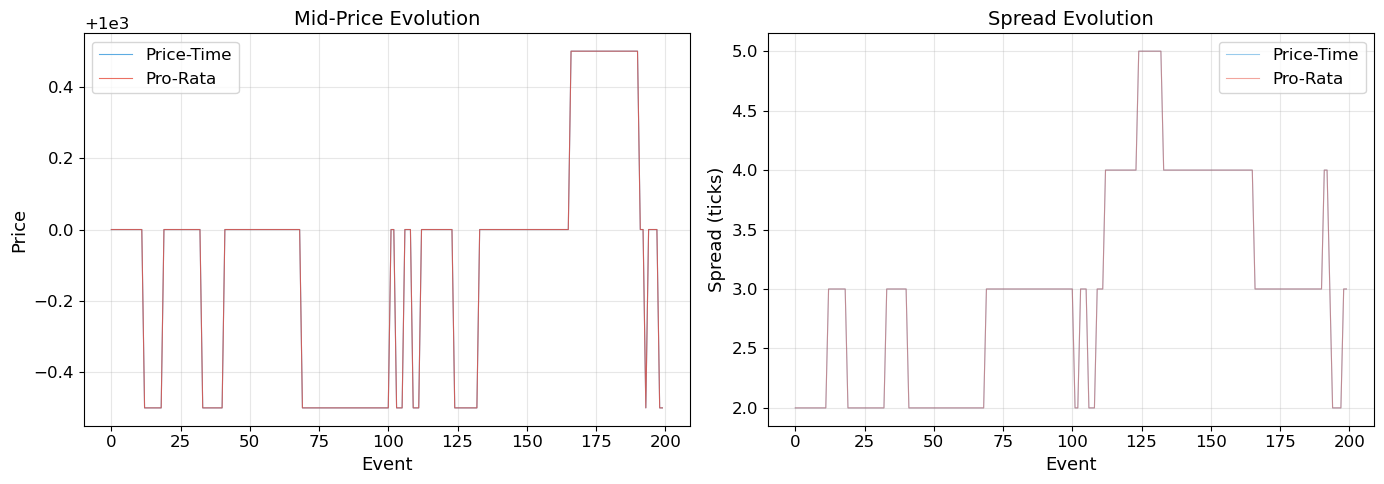

Volume comparison:
  Price-Time: 236 lots traded, mean spread = 3.01 ticks
  Pro-Rata: 236 lots traded, mean spread = 3.01 ticks


In [4]:
def run_comparison(n_events=200, seed=42):
    """Run the same order sequence through both engines."""
    rng = np.random.default_rng(seed)
    
    results = {}
    for name, engine_cls in [('Price-Time', PriceTimeEngine), ('Pro-Rata', ProRataEngine)]:
        reset_order_id_counter()
        book = OrderBook()
        engine = engine_cls()
        rng_copy = np.random.default_rng(seed)  # same sequence
        
        # Seed the book
        mid = 1000
        for i in range(1, 20):
            for _ in range(5):
                book.add_order(limit_order(mid - i, rng_copy.integers(1, 10), 0.0, Side.BID))
                book.add_order(limit_order(mid + i, rng_copy.integers(1, 10), 0.0, Side.ASK))
        
        mid_prices = []
        spreads = []
        total_fills = 0
        
        for i in range(n_events):
            side = Side.BID if rng_copy.random() < 0.5 else Side.ASK
            if rng_copy.random() < 0.3:  # 30% market orders
                size = rng_copy.integers(1, 8)
                order = market_order(size=size, timestamp=float(i), side=side)
            else:
                offset = rng_copy.integers(1, 15)
                p = (mid - offset) if side == Side.BID else (mid + offset)
                size = rng_copy.integers(1, 10)
                order = limit_order(price=p, size=size, timestamp=float(i), side=side)
            
            fills = engine.process(book, order)
            total_fills += sum(f.size for f in fills)
            
            if book.mid_price is not None:
                mid_prices.append(book.mid_price)
                spreads.append(book.spread)
        
        results[name] = {
            'mid_prices': np.array(mid_prices),
            'spreads': np.array(spreads),
            'total_volume': total_fills,
        }
    
    return results

results = run_comparison()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, color in [('Price-Time', '#3498db'), ('Pro-Rata', '#e74c3c')]:
    r = results[name]
    axes[0].plot(r['mid_prices'], label=name, alpha=0.8, color=color, linewidth=0.8)
    axes[1].plot(r['spreads'], label=name, alpha=0.5, color=color, linewidth=0.8)

axes[0].set_title('Mid-Price Evolution')
axes[0].set_xlabel('Event')
axes[0].set_ylabel('Price')
axes[0].legend()

axes[1].set_title('Spread Evolution')
axes[1].set_xlabel('Event')
axes[1].set_ylabel('Spread (ticks)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Volume comparison:")
for name, r in results.items():
    print(f"  {name}: {r['total_volume']} lots traded, "
          f"mean spread = {r['spreads'].mean():.2f} ticks")

## 4. Incentive Differences

The priority rule fundamentally changes trader incentives:

| | Price-Time | Pro-Rata |
|---|---|---|
| **Incentive** | Be first in the queue (speed) | Post large orders (size) |
| **Favors** | Fast traders (HFT) | Large traders |
| **Queue position** | Time of arrival | Size of order |
| **Common in** | Most equity exchanges | Some futures markets |

As Field and Large (2008) show, pro-rata matching can lead to order inflation: traders post larger orders than they actually want filled, knowing they'll only receive a proportional share.

## 5. State-Space Complexity

From the paper (Section 3.2): *"If there are $P$ different choices for price in a given LOB, then the state space of the current depth profile alone, expressed in units of the lot size $\sigma$, is $\mathbb{Z}^P$."*

This exponential state space is why modelling LOBs is fundamentally hard.

In [5]:
# Illustrate state-space explosion
print("State-space size for depth profile with max depth D at each of P price levels:")
print(f"{'P (prices)':>12} {'D (max depth)':>14} {'States':>20}")
print("-" * 50)
for P in [5, 10, 20, 50]:
    for D in [5, 10]:
        states = (2 * D + 1) ** P  # depth can range from -D to +D
        print(f"{P:>12} {D:>14} {states:>20,.0f}")

print("\nEven a tiny 10-price, 10-depth LOB has ~2.6 × 10^13 possible states!")
print("This is why dimensionality reduction is essential for LOB models.")

State-space size for depth profile with max depth D at each of P price levels:
  P (prices)  D (max depth)               States
--------------------------------------------------
           5              5              161,051
           5             10            4,084,101
          10              5       25,937,424,601
          10             10   16,679,880,978,201
          20              5 672,749,994,932,560,068,608
          20             10 278,218,429,446,951,562,911,940,608
          50              5 11,739,085,287,969,531,925,204,979,223,627,977,526,804,979,457,720,320
          50             10 1,291,114,435,050,719,025,102,335,048,162,877,960,979,105,964,611,644,878,863,680,405,504

Even a tiny 10-price, 10-depth LOB has ~2.6 × 10^13 possible states!
This is why dimensionality reduction is essential for LOB models.


## Summary

Key takeaways from Section 3 of the paper:

1. **Price-time priority** (FIFO) is the dominant matching rule — it rewards speed.
2. **Pro-rata matching** allocates proportionally to size — it rewards large orders.
3. The **state space** of an LOB is astronomically large ($\mathbb{Z}^P$), making exact solutions intractable.
4. There's a fundamental **feedback loop**: order flow depends on $L(t)$, and $L(t)$ depends on order flow.

**Next:** Notebook 03 introduces the Smith et al. (2003) zero-intelligence model.